<a href="https://colab.research.google.com/github/bhargavrrao-web/XAI_LABS-/blob/main/Lab_TCAV_NetworkDissection_FashionMNIST_1RUB25CSE0004.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab: Opening the Black Box of a Fashion Classifier
### Applying TCAV and Network Dissection on **Fashion-MNIST**

**Name:** Bhargav R Rao &nbsp;&nbsp;&nbsp; **USN:** 1RUB25CSE0004

**Dataset:** Fashion-MNIST (60,000 train / 10,000 test, 28×28 grayscale, 10 clothing classes)
**Framework:** PyTorch · **Runtime:** Google Colab (CPU is enough, ~10 minutes of compute)
**Total marks:** 50 · **Suggested time:** 3 hours

---

## Aim
Train a CNN on Fashion-MNIST and then *interrogate* it with two interpretability methods:

| Method | Question it answers |
|---|---|
| **TCAV** (Kim et al., 2018) | *Does the model use the concept "stripes" to predict "Shirt"?* (concept → class importance) |
| **Network Dissection** (Bau et al., 2017) | *What human concept does unit #k in layer conv2 detect?* (unit → concept alignment) |

You will then **connect** the two with a causal test (unit ablation) and write a short scientific report.

## Learning outcomes
After this lab you can:
1. Train a CNN and extract intermediate activations at chosen layers.
2. Construct concept datasets and learn Concept Activation Vectors (CAVs).
3. Compute TCAV scores with a statistical significance test.
4. Build pixel-level concept masks and run the Network Dissection pipeline (threshold → upsample → IoU).
5. Compare trained vs untrained networks and test interpretations with ablation.
6. Critically discuss confounds and limitations of both methods.

## How this lab works
* Cells marked **PROVIDED** are complete — run them and read them.
* Cells marked **YOUR TASK** contain `# TODO` sections you must complete.
* Written answers go into the **Answer** markdown cells.
* **Write your hypotheses *before* you run each experiment** — this is graded.

## Mark distribution

| Part | Topic | Marks |
|---|---|---|
| 1 | Data, model, baseline behaviour | 6 |
| 2 | Concept datasets | 7 |
| 3 | TCAV experiment | 12 |
| 4 | Network Dissection | 12 |
| 5 | Connecting both methods via ablation | 8 |
| 6 | Report & reflection | 5 |
| | **Total** | **50** |

## Part 0 — Setup *(PROVIDED)*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from scipy import ndimage, stats
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

SEED = 0
torch.manual_seed(SEED); np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

C_BLUE, C_ORANGE, C_AQUA, C_GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9a94"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

Using device: cuda


## Part 1 — Data, model and baseline behaviour *(6 marks)*

### 1.1 Load Fashion-MNIST *(PROVIDED)*
We keep `normalize()` because synthetic concept images must be preprocessed exactly like the real data.

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 205kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.82MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.0MB/s]


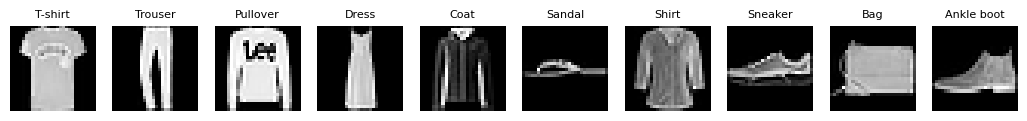

In [2]:
MEAN, STD = 0.2860, 0.3530
def normalize(x):                       # x in [0, 1]
    return (x - MEAN) / STD

tfm = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))])
train_ds = datasets.FashionMNIST("./data", train=True,  download=True, transform=tfm)
test_ds  = datasets.FashionMNIST("./data", train=False, download=True, transform=tfm)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader  = torch.utils.data.DataLoader(test_ds,  batch_size=512, shuffle=False)

CLASSES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
X_test_raw = test_ds.data.float() / 255.0      # (10000, 28, 28) in [0,1]
y_test     = test_ds.targets.clone()

fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for k, ax in enumerate(axes):
    ax.imshow(X_test_raw[(y_test == k).nonzero()[0].item()], cmap="gray")
    ax.set_title(CLASSES[k], fontsize=8); ax.axis("off")
plt.show()

### 1.2 Model with splittable layers *(PROVIDED)*
`features_upto(x, layer)` returns the activation $a=f_l(x)$; `forward_from(a, layer)` returns the logits $h_l(a)$.

```
input 1×28×28 → conv1 (16) → conv2 (32, after pool) → conv3 (64, after pool) → fc(128) → fc(10)
```

In [3]:
class SmallCNN(nn.Module):
    LAYERS = ["conv1", "conv2", "conv3"]
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, 3, padding=1)
        self.pool  = nn.MaxPool2d(2)
        self.fc1   = nn.Linear(64 * 7 * 7, 128)
        self.fc2   = nn.Linear(128, 10)

    def features_upto(self, x, layer):
        a = F.relu(self.conv1(x))
        if layer == "conv1": return a
        a = F.relu(self.conv2(self.pool(a)))
        if layer == "conv2": return a
        return F.relu(self.conv3(self.pool(a)))

    def forward_from(self, a, layer):
        if layer == "conv1":
            a = F.relu(self.conv2(self.pool(a))); layer = "conv2"
        if layer == "conv2":
            a = F.relu(self.conv3(self.pool(a)))
        a = torch.flatten(a, 1)
        return self.fc2(F.relu(self.fc1(a)))

    def forward(self, x):
        return self.forward_from(self.features_upto(x, "conv3"), "conv3")

@torch.no_grad()
def predict(net, X_raw, batch=512):
    """X_raw: (N,28,28) tensor in [0,1]. Returns predicted labels."""
    net.eval()
    out = []
    for i in range(0, len(X_raw), batch):
        x = normalize(X_raw[i:i+batch, None]).to(device)
        out.append(net(x).argmax(1).cpu())
    return torch.cat(out)

def evaluate(net):
    return (predict(net, X_test_raw) == y_test).float().mean().item()

model = SmallCNN().to(device)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
for epoch in range(3):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(); loss.backward(); opt.step()
    print(f"epoch {epoch+1}: test accuracy = {evaluate(model):.4f}")
model.eval();

epoch 1: test accuracy = 0.8696
epoch 2: test accuracy = 0.8824
epoch 3: test accuracy = 0.8985


### 1.3 YOUR TASK — Baseline behaviour *(6 marks)*

**(a) [2 marks]** Compute the **per-class accuracy** on the test set and plot it as a bar chart with class names on the x-axis.

**(b) [2 marks]** Compute the 10×10 **confusion matrix** (use `sklearn.metrics.confusion_matrix`) and display it. Name the **two most confused class pairs**.

**(c) [2 marks]** *Hypotheses (write before Part 3 and 4).* Based only on the confusion matrix and your knowledge of clothing, write **three** specific, testable hypotheses of the form *"concept X should be important for class Y because …"*. For example, *"vertical stripes should matter for Trousers because …"*.

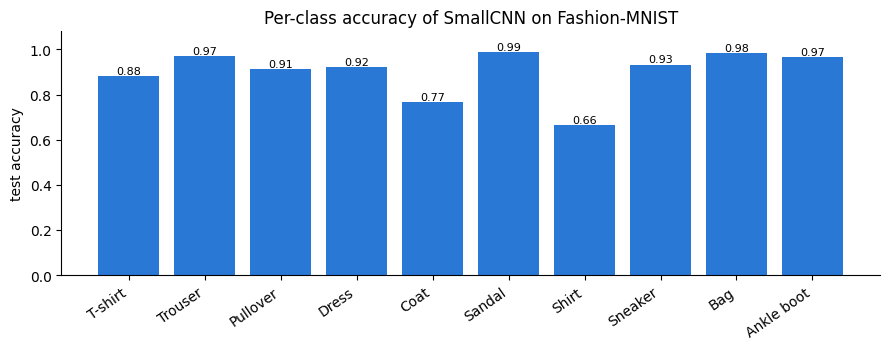

Overall accuracy: 0.8985


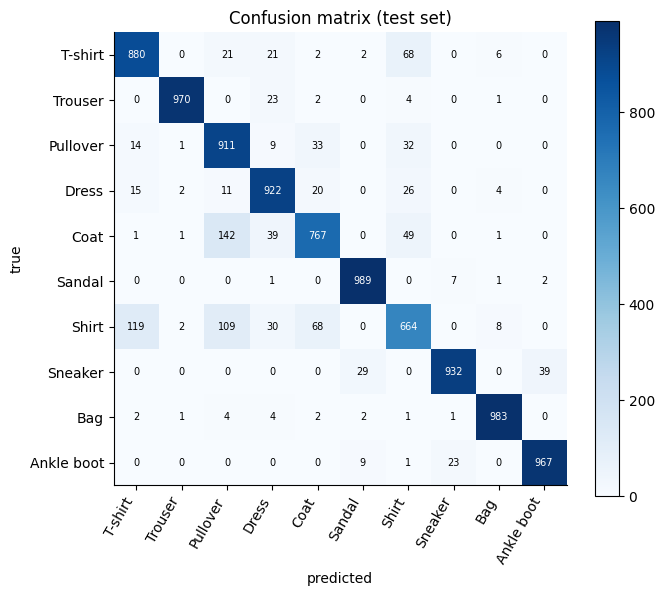

Most confused pair: T-shirt <-> Shirt: 187 mistakes (68 T-shirt predicted as Shirt, 119 the other way round)
Most confused pair: Pullover <-> Coat: 175 mistakes (33 Pullover predicted as Coat, 142 the other way round)


In [4]:
import pandas as pd
from sklearn.metrics import confusion_matrix

preds = predict(model, X_test_raw)

# (a) per-class accuracy
per_class_acc = np.array([(preds[y_test == k] == k).float().mean().item() for k in range(10)])
fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.bar(CLASSES, per_class_acc, color=C_BLUE)
for b, v in zip(bars, per_class_acc):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", fontsize=8)
ax.set_ylim(0, 1.08); ax.set_ylabel("test accuracy"); ax.set_title("Per-class accuracy of SmallCNN on Fashion-MNIST")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()
print("Overall accuracy:", round(float((preds == y_test).float().mean()), 4))

# (b) confusion matrix and the two most confused pairs
cm = confusion_matrix(y_test.numpy(), preds.numpy())
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=60, ha="right"); ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion matrix (test set)"); plt.colorbar(im); plt.tight_layout(); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pair_err = {(i, j): int(off[i, j] + off[j, i]) for i in range(10) for j in range(i + 1, 10)}
top2 = sorted(pair_err.items(), key=lambda kv: -kv[1])[:2]
for (i, j), n in top2:
    print(f"Most confused pair: {CLASSES[i]} <-> {CLASSES[j]}: {n} mistakes "
          f"({off[i, j]} {CLASSES[i]} predicted as {CLASSES[j]}, {off[j, i]} the other way round)")

**Answer 1(b) — two most confused pairs:**

*…*

**Answer 1(c) — my three hypotheses:**

1. *…*
2. *…*
3. *…*

---
## Part 2 — Concept datasets for TCAV *(7 marks)*

Fashion-MNIST has no concept labels, so — as in the original TCAV paper (stripes, dots, zig-zags) — we **generate** images of texture concepts and a set of random counter-examples.

| Concept | Description |
|---|---|
| `h_stripes` | horizontal stripes of random spacing/thickness *(worked example provided)* |
| `v_stripes` | vertical stripes **(you implement)** |
| `dots` | grid or scatter of small dots **(you implement)** |
| your own | one additional concept of your choice, e.g. `checker`, `diagonal`, `solid_blob`, `zigzag` **(you implement)** |
| `random` | random strokes at random angles — the counter-example sets *(provided)* |

### 2.1 Provided helpers

In [5]:
rng = np.random.default_rng(SEED)
H = W = 28

def _finish(img):
    img = ndimage.gaussian_filter(img, sigma=0.6)
    return np.clip(img / (img.max() + 1e-8), 0, 1)

def make_set(fn, n):
    imgs = np.stack([fn() for _ in range(n)])[:, None]          # (n,1,28,28) in [0,1]
    return normalize(torch.tensor(imgs, dtype=torch.float32))

def draw_line(img, r0, c0, r1, c1, thick):
    rr, cc = np.ogrid[:H, :W]
    for t in np.linspace(0, 1, 60):
        r, c = r0 + t * (r1 - r0), c0 + t * (c1 - c0)
        img[(rr - r) ** 2 + (cc - c) ** 2 <= (thick / 2) ** 2] = 1.0
    return img

def make_h_stripes():                                            # WORKED EXAMPLE
    img = np.zeros((H, W))
    gap, thick, off = rng.integers(4, 8), rng.integers(1, 3), rng.integers(0, 4)
    for r in range(off, H, gap):
        img[r:r + thick, 3:25] = 1.0
    return _finish(img)

def make_random():                                               # COUNTER-EXAMPLES
    img = np.zeros((H, W))
    for _ in range(rng.integers(1, 4)):
        r0, c0 = rng.uniform(7, 21, size=2)
        ang, L = rng.uniform(0, 2 * np.pi), rng.uniform(8, 16)
        r1 = np.clip(r0 + L * np.sin(ang), 2, 25); c1 = np.clip(c0 + L * np.cos(ang), 2, 25)
        draw_line(img, r0, c0, r1, c1, rng.uniform(2, 3.5))
    return _finish(img)

### 2.2 YOUR TASK — Implement the concept generators *(5 marks)*

**(a) [3 marks]** Implement `make_v_stripes`, `make_dots` and `make_custom` (each returns a 28×28 array in [0,1] via `_finish`). Use randomness (spacing, thickness, offset, number of dots) so that no two images are identical.

**(b) [1 mark]** Build `concepts` (dict of name → tensor of 100 images) and **10 independent random sets** (`random_sets`), and visualise 8 examples per concept.

**(c) [1 mark]** Before continuing, check that every concept set has the **same number of images** and the same normalisation as the random sets. State one reason why mismatched image statistics would be a problem.

h_stripes       shape=(100, 1, 28, 28)  mean=-0.069  std=1.009  min=-0.81  max=+2.02
v_stripes       shape=(100, 1, 28, 28)  mean=-0.036  std=1.028  min=-0.81  max=+2.02
dots            shape=(100, 1, 28, 28)  mean=-0.492  std=0.688  min=-0.81  max=+2.02
diagonal        shape=(100, 1, 28, 28)  mean=-0.086  std=1.005  min=-0.81  max=+2.02
random_sets[0]  shape=(100, 1, 28, 28)  mean=-0.580  std=0.668  min=-0.81  max=+2.02
random_sets[9]  shape=(100, 1, 28, 28)  mean=-0.558  std=0.694  min=-0.81  max=+2.02


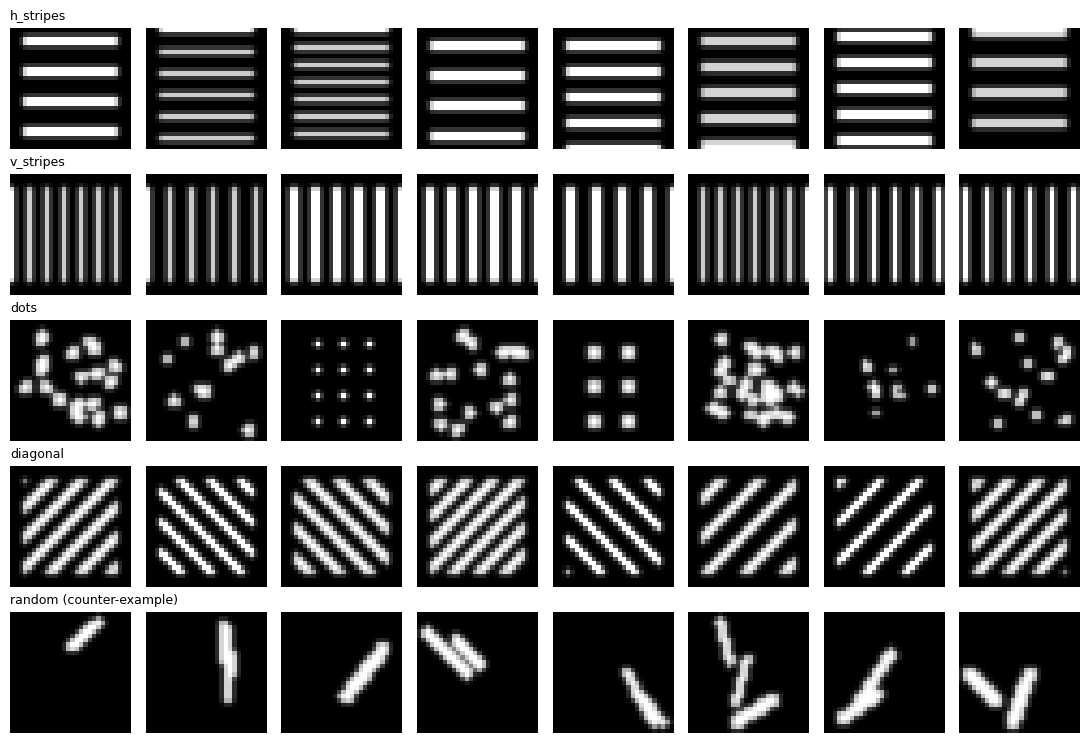

In [6]:
def make_v_stripes():
    img = np.zeros((H, W))
    gap, thick, off = rng.integers(4, 8), rng.integers(1, 3), rng.integers(0, 4)
    for c in range(off, W, gap):
        img[3:25, c:c + thick] = 1.0
    return _finish(img)

def make_dots():
    img = np.zeros((H, W)); rr, cc = np.ogrid[:H, :W]
    rad = rng.uniform(0.9, 1.7)
    if rng.random() < 0.5:                                   # regular grid of dots
        gap = rng.integers(5, 9); off_r, off_c = rng.integers(0, gap, size=2)
        centres = [(r, c) for r in range(3 + off_r, 25, gap) for c in range(3 + off_c, 25, gap)]
    else:                                                    # random scatter
        centres = [tuple(rng.uniform(3, 25, size=2)) for _ in range(rng.integers(12, 30))]
    for r, c in centres:
        img[(rr - r) ** 2 + (cc - c) ** 2 <= rad ** 2] = 1.0
    return _finish(img)

def make_custom():
    """own concept: DIAGONAL stripes with random direction, spacing, thickness and offset"""
    rr, cc = np.mgrid[:H, :W]
    gap, thick, off, sign = rng.integers(6, 10), rng.integers(2, 4), rng.integers(0, 6), rng.choice([-1, 1])
    img = (((rr + sign * cc + off) % gap) < thick).astype(float)
    img[:3] = 0; img[-3:] = 0; img[:, :3] = 0; img[:, -3:] = 0
    return _finish(img)

N_CONCEPT, N_RANDOM_SETS = 100, 10
CUSTOM_NAME = "diagonal"
concepts = {"h_stripes": make_set(make_h_stripes, N_CONCEPT), "v_stripes": make_set(make_v_stripes, N_CONCEPT),
            "dots": make_set(make_dots, N_CONCEPT), CUSTOM_NAME: make_set(make_custom, N_CONCEPT)}
random_sets = [make_set(make_random, N_CONCEPT) for _ in range(N_RANDOM_SETS)]

# (c) consistency check: same size and same normalisation for concept and random sets
for name, t in list(concepts.items()) + [("random_sets[0]", random_sets[0]), ("random_sets[9]", random_sets[9])]:
    print(f"{name:15s} shape={tuple(t.shape)}  mean={t.mean():+.3f}  std={t.std():.3f}  min={t.min():+.2f}  max={t.max():+.2f}")
assert all(len(t) == N_CONCEPT for t in list(concepts.values()) + random_sets), "all sets must have the same size"

# (b) 8 examples of every concept and of one random set
def show_rows(rows, titles):
    fig, axes = plt.subplots(len(rows), 8, figsize=(11, 1.5 * len(rows)))
    for r, (t, title) in enumerate(zip(rows, titles)):
        for j in range(8):
            axes[r, j].imshow((t[j, 0] * STD + MEAN).numpy(), cmap="gray", vmin=0, vmax=1); axes[r, j].axis("off")
        axes[r, 0].set_title(title, fontsize=9, loc="left")
    plt.tight_layout(); plt.show()
show_rows(list(concepts.values()) + [random_sets[0]], list(concepts) + ["random (counter-example)"])

### 2.3 YOUR TASK — Sanity check with the model *(2 marks)*
Feed each concept set to the trained network and plot the **distribution of predicted classes** for every concept (a small bar chart per concept).

**Answer:** Which classes does the network assign to your concept images? Does this already hint at what the concept "looks like" to the model? Why is a prediction histogram *not* a substitute for TCAV?

*…*

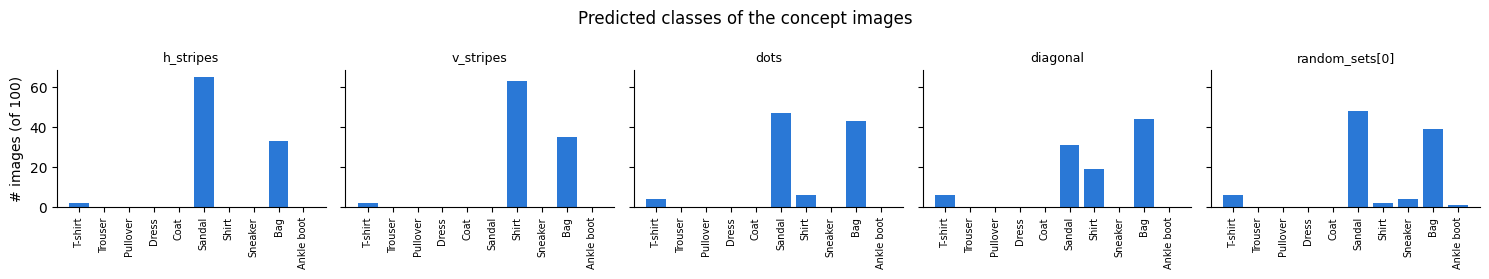

h_stripes       -> Sandal 65, Bag 33, T-shirt 2
v_stripes       -> Shirt 63, Bag 35, T-shirt 2
dots            -> Sandal 47, Bag 43, Shirt 6
diagonal        -> Bag 44, Sandal 31, Shirt 19
random_sets[0]  -> Sandal 48, Bag 39, T-shirt 6


In [7]:
@torch.no_grad()
def predict_normalised(x, batch=256):
    model.eval()
    return torch.cat([model(x[i:i + batch].to(device)).argmax(1).cpu() for i in range(0, len(x), batch)])

sets_to_show = {**concepts, "random_sets[0]": random_sets[0]}
fig, axes = plt.subplots(1, len(sets_to_show), figsize=(15, 2.8), sharey=True)
for ax, (name, imgs) in zip(axes, sets_to_show.items()):
    hist = np.bincount(predict_normalised(imgs).numpy(), minlength=10)
    ax.bar(range(10), hist, color=C_BLUE); ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=90, fontsize=7)
    ax.set_title(name, fontsize=9)
axes[0].set_ylabel("# images (of 100)"); plt.suptitle("Predicted classes of the concept images"); plt.tight_layout(); plt.show()
for name, imgs in sets_to_show.items():
    h = np.bincount(predict_normalised(imgs).numpy(), minlength=10)
    top = np.argsort(-h)[:3]
    print(f"{name:15s} -> " + ", ".join(f"{CLASSES[k]} {h[k]}" for k in top))

---
## Part 3 — TCAV experiment *(12 marks)*

**Recall the recipe.** For layer $l$ and concept $C$:
1. Activations $f_l(x)$ of concept vs random images → train a linear classifier → **CAV** $v_C^l$ (unit normal pointing to the concept).
2. Conceptual sensitivity: $S_{C,k,l}(x)=\nabla h_{l,k}(f_l(x))\cdot v_C^l$
3. $\text{TCAV}_{C,k,l}=\dfrac{|\{x\in X_k: S_{C,k,l}(x)>0\}|}{|X_k|}$
4. Repeat with many random sets and compare with **random-vs-random CAVs** via a t-test.

### 3.1 Provided helpers

In [8]:
@torch.no_grad()
def get_acts(x, layer, batch=256):
    out = [model.features_upto(x[i:i+batch].to(device), layer).flatten(1).cpu()
           for i in range(0, len(x), batch)]
    return torch.cat(out).numpy()

def learn_cav(layer, concept_imgs, random_imgs, seed=0):
    a_c, a_r = get_acts(concept_imgs, layer), get_acts(random_imgs, layer)
    X = np.concatenate([a_c, a_r]); y = np.r_[np.ones(len(a_c)), np.zeros(len(a_r))]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=seed, stratify=y)
    clf = LogisticRegression(C=0.1, max_iter=2000).fit(Xtr, ytr)
    cav = clf.coef_[0] / np.linalg.norm(clf.coef_[0])
    return cav, clf.score(Xte, yte)

def class_grads(layer, k, n=300):
    """Gradient of logit_k w.r.t. the layer activations for n test images of class k."""
    x = normalize(X_test_raw[y_test == k][:n, None]).to(device)
    a = model.features_upto(x, layer).detach().requires_grad_(True)
    logit_k = model.forward_from(a, layer)[:, k]
    grad, = torch.autograd.grad(logit_k.sum(), a)
    return grad.flatten(1).cpu().numpy()

def tcav_score(grads, cav):
    return float(np.mean(grads @ cav > 0))

### 3.2 YOUR TASK — CAV quality *(2 marks)*
For **every concept and every layer** (conv1, conv2, conv3) learn one CAV against `random_sets[0]` and report the held-out CAV accuracy in a table (rows = concepts, columns = layers).

**Answer:** Explain why a high CAV accuracy does **not** prove that the concept matters for classification. Which layer separates your concepts best, and does that match your expectation?

*…*

In [9]:
cav_acc = pd.DataFrame({layer: {c: learn_cav(layer, imgs, random_sets[0])[1] for c, imgs in concepts.items()}
                        for layer in SmallCNN.LAYERS})
print("Held-out CAV accuracy (concept vs random_sets[0]):")
display(cav_acc.round(3))
print("Best layer per concept:", cav_acc.idxmax(axis=1).to_dict())
print("Mean accuracy per layer:", cav_acc.mean().round(3).to_dict())

Held-out CAV accuracy (concept vs random_sets[0]):


,conv1,conv2,conv3
h_stripes,1.0,1.000,1.000
v_stripes,1.0,1.000,1.000
dots,0.9,0.967,0.983
diagonal,1.0,1.000,1.000


Best layer per concept: {'h_stripes': 'conv1', 'v_stripes': 'conv1', 'dots': 'conv3', 'diagonal': 'conv1'}
Mean accuracy per layer: {'conv1': 0.975, 'conv2': 0.992, 'conv3': 0.996}


### 3.3 YOUR TASK — Full TCAV with significance test *(6 marks)*

**(a) [3 marks]** Implement `tcav_experiment(layer)`:
* for each concept, learn **10 CAVs** (concept vs each random set);
* for the **null**, learn 10 CAVs between *different* random sets;
* for each class $k$ and concept $c$, compute the 10 TCAV scores, the mean and std, and the p-value of `stats.ttest_ind(scores, null_scores)`.

**(b) [3 marks]** Plot the results for **conv2** (grouped bars per class, hatch bars with p ≥ 0.05, dashed line at 0.5) and produce the same plot for **conv1** and **conv3**.

> Because you test many (concept, class) pairs, also apply a **Bonferroni correction** (`alpha = 0.05 / n_tests`) and mark which results survive. Report how many significant results are lost.

40 tests per layer -> Bonferroni alpha = 0.00125


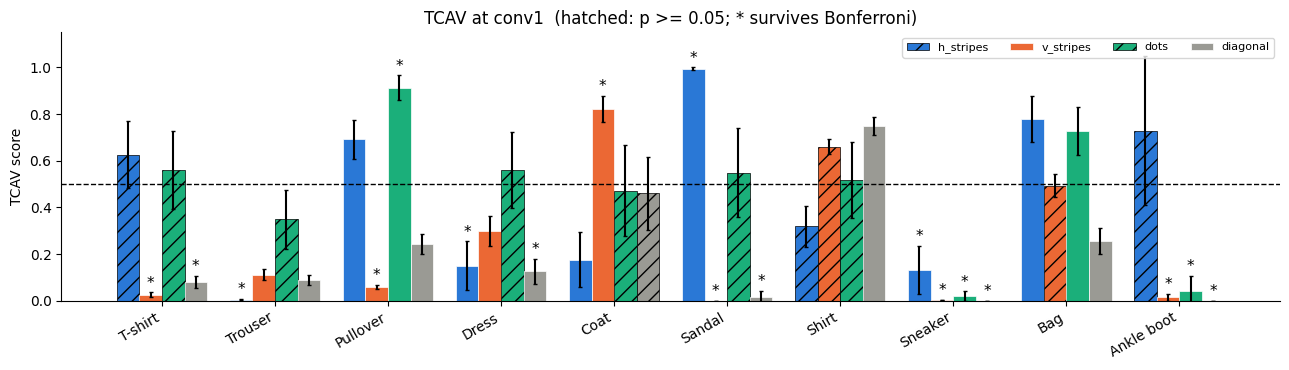

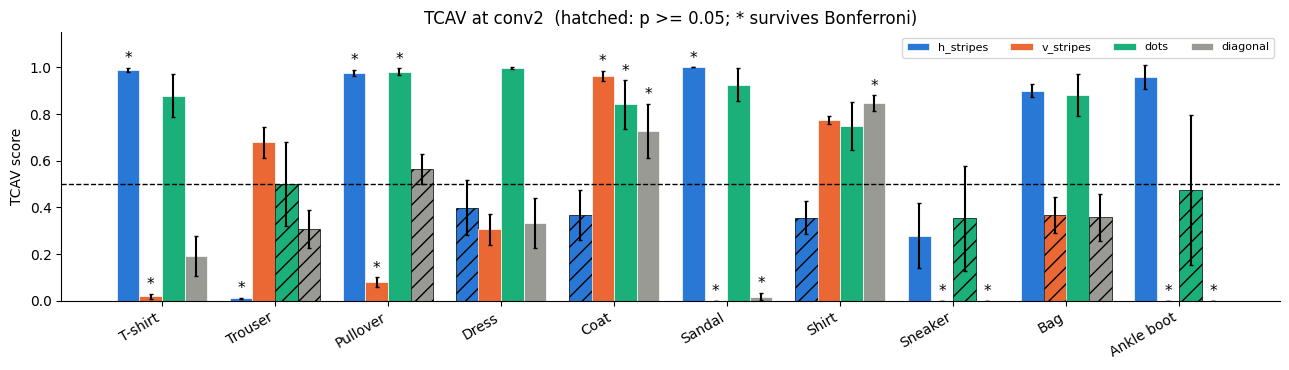

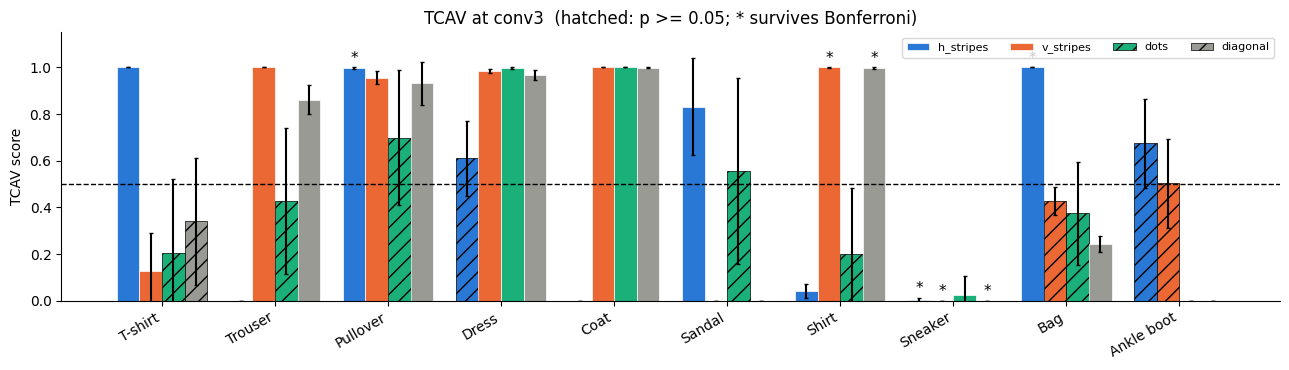

,significant (p < 0.05),survive Bonferroni,lost to correction
conv1,28,18,10
conv2,30,17,13
conv3,29,7,22


Strongest results that survive the Bonferroni correction:


,layer,concept,class,TCAV,std,p,Bonferroni,|TCAV-0.5|
0,conv1,v_stripes,Sandal,0.0,0.0,0.000,True,0.5
1,conv3,diagonal,Sneaker,0.0,0.0,0.001,True,0.5
2,conv2,v_stripes,Sneaker,0.0,0.0,0.000,True,0.5
3,conv2,v_stripes,Ankle boot,0.0,0.0,0.001,True,0.5
4,conv2,diagonal,Sneaker,0.0,0.0,0.000,True,0.5
5,conv2,diagonal,Ankle boot,0.0,0.0,0.001,True,0.5
6,conv2,h_stripes,Sandal,1.0,0.0,0.000,True,0.5
7,conv2,v_stripes,Sandal,0.0,0.0,0.000,True,0.5
8,conv1,diagonal,Ankle boot,0.0,0.0,0.000,True,0.5
9,conv1,diagonal,Sneaker,0.0,0.0,0.000,True,0.5


In [10]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)      # t-tests on constant scores (0 or 1) are harmless

def tcav_experiment(layer, classes=range(10)):
    """returns {(concept, class): (mean, std, p_value)}"""
    classes = list(classes)
    grads = {k: class_grads(layer, k) for k in classes}
    # null CAVs: random set i versus a DIFFERENT random set (i+1)
    null_cavs = [learn_cav(layer, random_sets[i], random_sets[(i + 1) % N_RANDOM_SETS], seed=i)[0] for i in range(N_RANDOM_SETS)]
    out = {}
    for c, imgs in concepts.items():
        cavs = [learn_cav(layer, imgs, random_sets[i], seed=i)[0] for i in range(N_RANDOM_SETS)]   # concept vs each random set
        for k in classes:
            s = np.array([tcav_score(grads[k], v) for v in cavs])
            s0 = np.array([tcav_score(grads[k], v) for v in null_cavs])
            p = stats.ttest_ind(s, s0).pvalue
            out[(c, k)] = (float(s.mean()), float(s.std()), 1.0 if np.isnan(p) else float(p))
    return out

N_TESTS = len(concepts) * 10                    # (concept, class) pairs per layer
ALPHA, ALPHA_BONF = 0.05, 0.05 / N_TESTS
print(f"{N_TESTS} tests per layer -> Bonferroni alpha = {ALPHA_BONF:.5f}")

def plot_tcav(res, layer):
    names = list(concepts); colours = [C_BLUE, C_ORANGE, C_AQUA, C_GRAY]
    fig, ax = plt.subplots(figsize=(13, 3.8)); w = 0.2
    for ci, c in enumerate(names):
        for k in range(10):
            m, s, p = res[(c, k)]
            ax.bar(k + (ci - 1.5) * w, m, w, yerr=s, color=colours[ci], capsize=1.5, ecolor="k",
                   hatch="//" if p >= ALPHA else None, edgecolor="white" if p < ALPHA else "k", linewidth=0.5,
                   label=c if k == 0 else None)
            if p < ALPHA_BONF:
                ax.text(k + (ci - 1.5) * w, min(m + s, 1.0) + 0.02, "*", ha="center", fontsize=11)
    ax.axhline(0.5, ls="--", color="k", lw=1); ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=30, ha="right")
    ax.set_ylim(0, 1.15); ax.set_ylabel("TCAV score"); ax.set_title(f"TCAV at {layer}  (hatched: p >= 0.05; * survives Bonferroni)")
    ax.legend(ncol=4, fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

tcav_results = {}
for layer in SmallCNN.LAYERS:
    tcav_results[layer] = tcav_experiment(layer)
    plot_tcav(tcav_results[layer], layer)

summary = pd.DataFrame({layer: {"significant (p < 0.05)": sum(v[2] < ALPHA for v in r.values()),
                                "survive Bonferroni": sum(v[2] < ALPHA_BONF for v in r.values())}
                        for layer, r in tcav_results.items()}).T
summary["lost to correction"] = summary["significant (p < 0.05)"] - summary["survive Bonferroni"]
display(summary)

rows = [{"layer": l, "concept": c, "class": CLASSES[k], "TCAV": m, "std": s, "p": p, "Bonferroni": p < ALPHA_BONF}
        for l, r in tcav_results.items() for (c, k), (m, s, p) in r.items() if p < ALPHA_BONF]
strongest = pd.DataFrame(rows)
if len(strongest):
    strongest["|TCAV-0.5|"] = (strongest["TCAV"] - 0.5).abs()
    print("Strongest results that survive the Bonferroni correction:")
    display(strongest.sort_values("|TCAV-0.5|", ascending=False).head(12).round(3).reset_index(drop=True))

### 3.4 YOUR TASK — Interpretation *(4 marks, counted in Part 3)*
Return to your three hypotheses from Part 1(c).

| Hypothesis | Supported? (yes / no / inconclusive) | Evidence (concept, class, layer, TCAV score, p-value) |
|---|---|---|
| 1 | | |
| 2 | | |
| 3 | | |

**Answer:** Describe **one surprising result** and propose a **confound** that could explain it (think: overall brightness, amount of "ink", spatial location, image texture vs shape). How would you redesign the concept set to test your confound?

*…*

---
## Part 4 — Network Dissection *(12 marks)*

Network Dissection labels individual units:
1. Collect activation maps $A_k(x)$.
2. Threshold $T_k$: top 0.5 % of all activations of unit $k$.
3. Bilinearly upsample $A_k(x)$ to 28×28 and binarise → $M_k(x)$.
4. $IoU_{k,c}=\dfrac{\sum_x|M_k(x)\cap L_c(x)|}{\sum_x|M_k(x)\cup L_c(x)|}$
5. Label the unit with the best concept; call it a *detector* if IoU > 0.04.

### 4.1 YOUR TASK — Build a "mini-Broden" for Fashion-MNIST *(4 marks)*
Complete `concept_masks(img, label)` so it returns boolean 28×28 masks for these concepts:

| Category | Concept | Mask definition |
|---|---|---|
| colour | `foreground` | pixels with intensity > 0.3 |
| colour | `background` | pixels with intensity < 0.05 |
| edge | `h-edge` | strong row-gradient (Sobel axis 0) dominating column-gradient |
| edge | `v-edge` | strong column-gradient (Sobel axis 1) dominating row-gradient |
| part | `hole` | enclosed background regions (`binary_fill_holes`), e.g. bag handles, gaps between shoe straps |
| part | `upper-half` | foreground pixels in rows 0–13 *(you add this)* |
| part | one more of your own | e.g. `bright-core` (intensity > 0.8), `boundary` (foreground minus eroded foreground) |
| object | `class-0` … `class-9` | foreground pixels, **only** in images of that class |

**Also answer:** What fraction of all pixels belong to each concept mask? Are any concepts so rare that IoU will be unreliable? (Report a bar chart of pixel fractions.)

Concepts: ['foreground', 'background', 'h-edge', 'v-edge', 'hole', 'upper-half', 'boundary', 'class-0', 'class-1', 'class-2', 'class-3', 'class-4', 'class-5', 'class-6', 'class-7', 'class-8', 'class-9'] | mask tensor: (1000, 17, 28, 28)


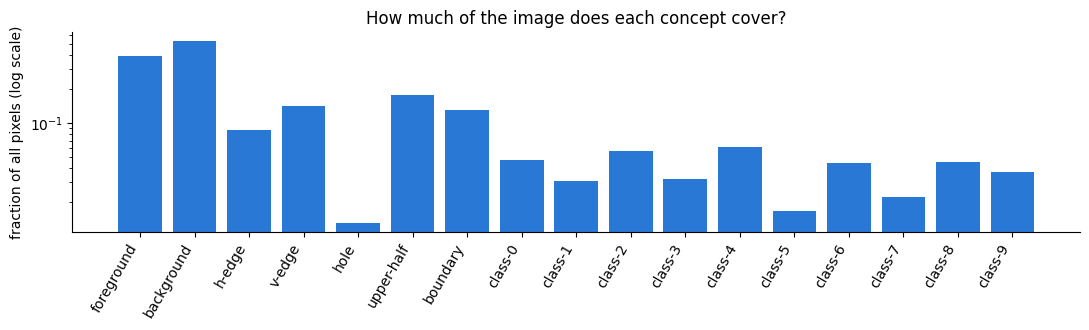

foreground    0.3941
background    0.5297
h-edge        0.0876
v-edge        0.1434
hole          0.0132
upper-half    0.1790
boundary      0.1304
class-0       0.0476
class-1       0.0308
class-2       0.0569
class-3       0.0318
class-4       0.0613
class-5       0.0166
class-6       0.0447
class-7       0.0223
class-8       0.0452
class-9       0.0368

Concepts covering < 1 % of pixels (IoU may be unreliable): []


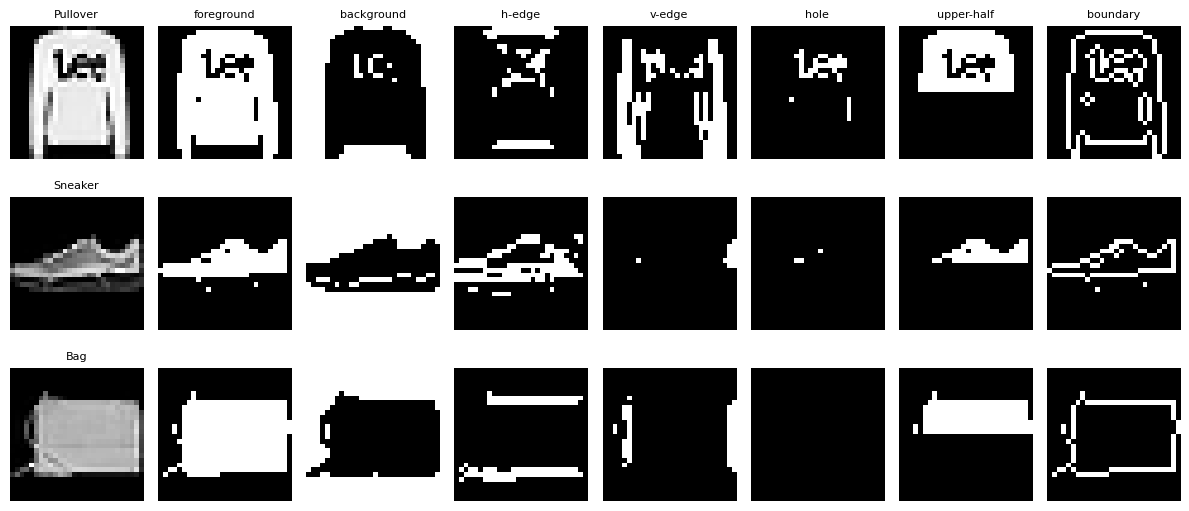

In [11]:
N_DISSECT = 1000
Xd = X_test_raw[:N_DISSECT].numpy()
yd = y_test[:N_DISSECT].numpy()

def concept_masks(img, label):
    fg = img > 0.3
    gy, gx = ndimage.sobel(img, axis=0), ndimage.sobel(img, axis=1)
    filled = ndimage.binary_fill_holes(fg)
    upper = fg.copy(); upper[14:] = False
    m = {
        "foreground": fg,
        "background": img < 0.05,
        "h-edge": (np.abs(gy) > 1.0) & (np.abs(gy) > 1.5 * np.abs(gx)),     # strong row-gradient dominates
        "v-edge": (np.abs(gx) > 1.0) & (np.abs(gx) > 1.5 * np.abs(gy)),     # strong column-gradient dominates
        "hole": filled & ~fg,                                                # enclosed background
        "upper-half": upper,                                                 # foreground in rows 0-13
        "boundary": fg & ~ndimage.binary_erosion(fg),                       # own concept: outline of the object
    }
    for d in range(10):
        m[f"class-{d}"] = fg if label == d else np.zeros_like(fg)
    return m

CONCEPTS = list(concept_masks(Xd[0], yd[0]).keys())
L = torch.tensor(np.stack([np.stack([concept_masks(im, lb)[c] for c in CONCEPTS])
                           for im, lb in zip(Xd, yd)]))          # (N, n_concepts, 28, 28)
print("Concepts:", CONCEPTS, "| mask tensor:", tuple(L.shape))

# pixel fraction of each concept
frac = L.float().mean(dim=(0, 2, 3)).numpy()
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(CONCEPTS, frac, color=C_BLUE); ax.set_yscale("log"); ax.set_ylabel("fraction of all pixels (log scale)")
ax.set_title("How much of the image does each concept cover?"); plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()
print(pd.Series(frac, index=CONCEPTS).round(4).to_string())
rare = [c for c, f in zip(CONCEPTS, frac) if f < 0.01]
print("\nConcepts covering < 1 % of pixels (IoU may be unreliable):", rare)

# masks for three different classes (Pullover, Sneaker, Bag)
show_c = ["foreground", "background", "h-edge", "v-edge", "hole", "upper-half", "boundary"]
fig, axes = plt.subplots(3, 1 + len(show_c), figsize=(12, 5.4))
for r, cls in enumerate([2, 7, 8]):
    i = int(np.where(yd == cls)[0][0])
    axes[r, 0].imshow(Xd[i], cmap="gray"); axes[r, 0].set_title(CLASSES[cls], fontsize=8); axes[r, 0].axis("off")
    for j, c in enumerate(show_c):
        axes[r, j + 1].imshow(L[i, CONCEPTS.index(c)], cmap="gray"); axes[r, j + 1].axis("off")
        if r == 0: axes[r, j + 1].set_title(c, fontsize=8)
plt.tight_layout(); plt.show()

### 4.2 Dissection algorithm *(PROVIDED — read it carefully)*

In [12]:
@torch.no_grad()
def dissect(net, layer, quantile=0.995, iou_thresh=0.04, batch=200):
    net.eval()
    x = normalize(torch.tensor(Xd)[:, None]).to(device)
    A = torch.cat([net.features_upto(x[i:i+batch], layer).cpu() for i in range(0, len(x), batch)])
    n_units = A.shape[1]
    flat = A.transpose(0, 1).reshape(n_units, -1).numpy()
    T = torch.tensor(np.quantile(flat, quantile, axis=1), dtype=torch.float32)

    inter = torch.zeros(n_units, len(CONCEPTS)); size_M = torch.zeros(n_units)
    size_L = L.flatten(2).sum((0, 2)).float()
    for i in range(0, len(A), batch):
        up = F.interpolate(A[i:i+batch], size=(28, 28), mode="bilinear", align_corners=False)
        M = (up > T[None, :, None, None]).flatten(2).float()
        Lb = L[i:i+batch].flatten(2).float()
        inter += torch.einsum("bup,bcp->uc", M, Lb)
        size_M += M.sum((0, 2))
    iou = inter / (size_M[:, None] + size_L[None, :] - inter + 1e-8)
    best = iou.argmax(1)
    rows = [{"unit": u, "concept": CONCEPTS[best[u]], "iou": iou[u, best[u]].item(),
             "detector": iou[u, best[u]].item() > iou_thresh} for u in range(n_units)]
    return rows, A, T, iou

dissection = {layer: dissect(model, layer) for layer in SmallCNN.LAYERS}
for layer, (rows, _, _, _) in dissection.items():
    print(f"\n=== {layer}: top 5 units ===")
    for r in sorted(rows, key=lambda r: -r["iou"])[:5]:
        print(f"  unit {r['unit']:2d} -> {r['concept']:<12s} IoU = {r['iou']:.3f}")


=== conv1: top 5 units ===
  unit 11 -> h-edge       IoU = 0.057
  unit  1 -> h-edge       IoU = 0.055
  unit  4 -> h-edge       IoU = 0.043
  unit  0 -> class-1      IoU = 0.041
  unit  9 -> boundary     IoU = 0.038

=== conv2: top 5 units ===
  unit 22 -> class-5      IoU = 0.028
  unit 19 -> class-1      IoU = 0.021
  unit 24 -> class-5      IoU = 0.017
  unit 13 -> class-5      IoU = 0.016
  unit  1 -> class-5      IoU = 0.015

=== conv3: top 5 units ===
  unit 35 -> class-1      IoU = 0.029
  unit 14 -> class-1      IoU = 0.025
  unit 37 -> class-5      IoU = 0.022
  unit 55 -> class-1      IoU = 0.021
  unit  4 -> class-5      IoU = 0.021


### 4.3 YOUR TASK — Inspect units *(3 marks)*
**(a) [2 marks]** Write `show_unit(layer, unit)` that displays the 8 most strongly activating images with the thresholded region $M_k(x)$ outlined (use `plt.contour`). Show the **best unit of each layer**.

**(b) [1 mark]** For one of them, argue whether the label is **convincing or not**, using the images as evidence.

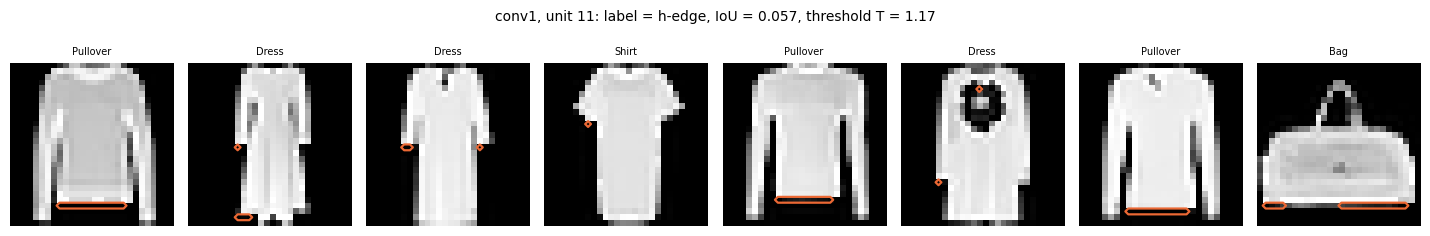

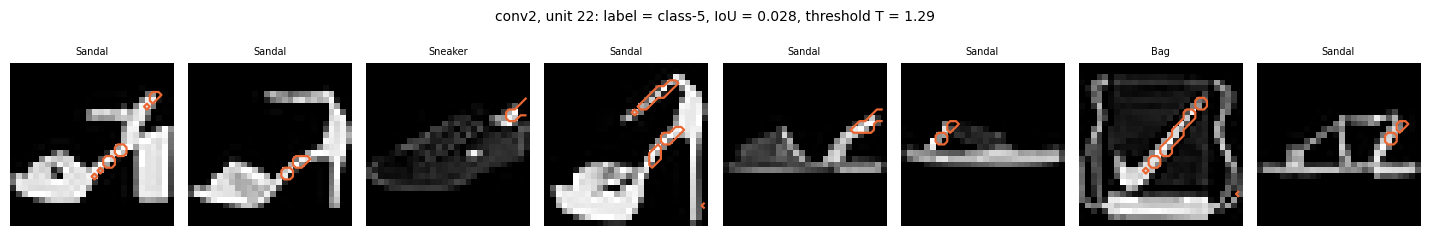

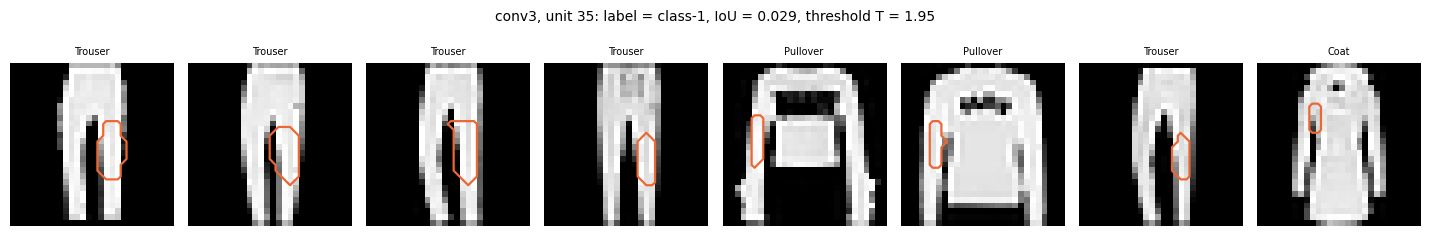

In [13]:
def show_unit(layer, unit, n=8):
    rows, A, T, _ = dissection[layer]
    info = rows[unit]
    strength = A[:, unit].flatten(1).max(dim=1).values                      # strongest activation of the unit per image
    top = strength.topk(n).indices
    up = F.interpolate(A[top, unit][:, None], size=(28, 28), mode="bilinear", align_corners=False)[:, 0]
    fig, axes = plt.subplots(1, n, figsize=(1.8 * n, 2.5))
    for ax, i, u_map in zip(axes, top.tolist(), up):
        ax.imshow(Xd[i], cmap="gray")
        region = (u_map > T[unit]).numpy().astype(float)                     # thresholded region M_k(x)
        if region.any():
            ax.contour(region, levels=[0.5], colors=C_ORANGE, linewidths=1.6)
        ax.set_title(CLASSES[yd[i]], fontsize=7); ax.axis("off")
    fig.suptitle(f"{layer}, unit {unit}: label = {info['concept']}, IoU = {info['iou']:.3f}, threshold T = {T[unit]:.2f}", fontsize=10)
    plt.tight_layout(); plt.show()

for layer in SmallCNN.LAYERS:
    best = max(dissection[layer][0], key=lambda r: r["iou"])
    show_unit(layer, best["unit"])

**Answer 4.3(b):**

*…*

### 4.4 YOUR TASK — Concepts across depth, and the untrained control *(5 marks)*

**(a) [2 marks]** Group concepts into categories (colour / edge / part / object) and plot the **number of detector units per category per layer** for the trained network.

**(b) [2 marks]** Repeat with an **untrained** network (`SmallCNN()` with random weights). Show both plots side by side.

**(c) [1 mark]** *Threshold sensitivity:* rerun `dissect` on conv2 with `quantile = 0.99` and `0.999`. What percentage of unit labels remain unchanged compared with 0.995?

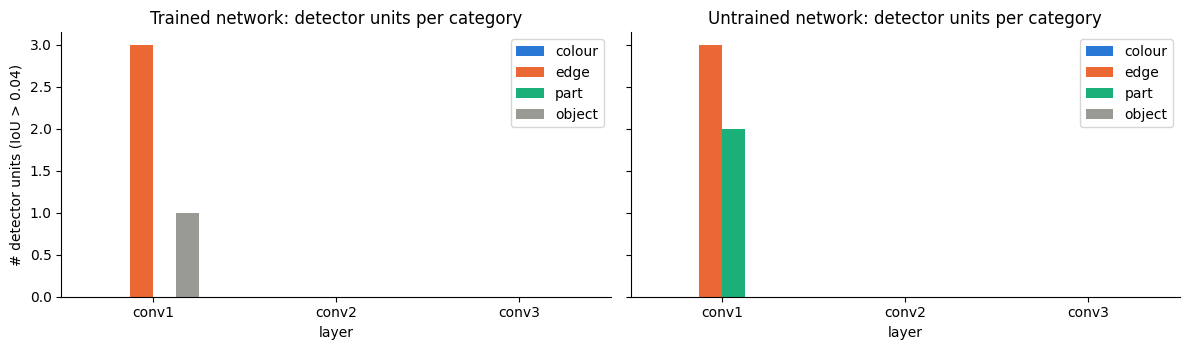

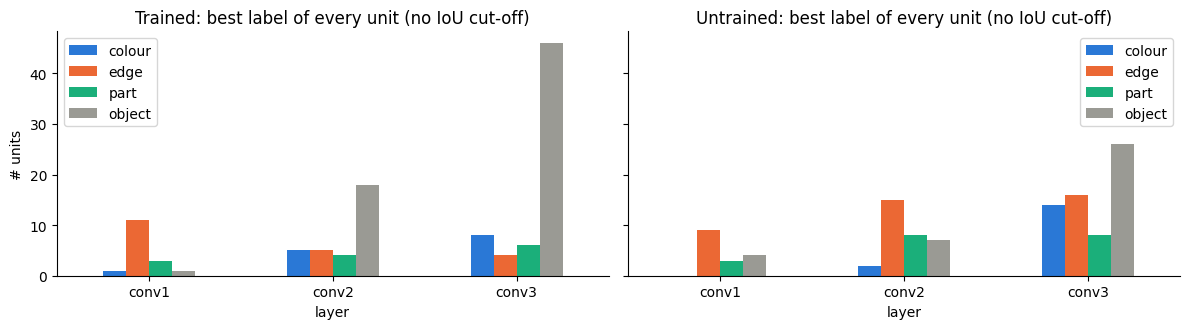

Trained:


,colour,edge,part,object,total,units
conv1,0,3,0,1,4,16
conv2,0,0,0,0,0,32
conv3,0,0,0,0,0,64


Untrained:


,colour,edge,part,object,total,units
conv1,0,3,2,0,5,16
conv2,0,0,0,0,0,32
conv3,0,0,0,0,0,64


Mean best IoU per layer  trained: {'conv1': 0.033, 'conv2': 0.007, 'conv3': 0.008} | untrained: {'conv1': 0.04, 'conv2': 0.006, 'conv3': 0.007}
quantile 0.99: 88 % of all unit labels unchanged vs 0.995 | n/a (no unit of conv2 is a detector at 0.995)
quantile 0.999: 56 % of all unit labels unchanged vs 0.995 | n/a (no unit of conv2 is a detector at 0.995)


In [14]:
CATEGORY = {"foreground": "colour", "background": "colour", "h-edge": "edge", "v-edge": "edge"}
CATEGORY.update({"hole": "part", "upper-half": "part", "boundary": "part"})
CATEGORY.update({f"class-{d}": "object" for d in range(10)})
CATS = ["colour", "edge", "part", "object"]
from collections import Counter

def counts_per_category(diss):
    out = {}
    for layer, (rows, _, _, _) in diss.items():
        cnt = Counter(CATEGORY[r["concept"]] for r in rows if r["detector"])
        out[layer] = [cnt.get(c, 0) for c in CATS]
    return pd.DataFrame(out, index=CATS).T            # rows = layers, columns = categories

# (a) trained network   (b) untrained control (random weights, same architecture)
torch.manual_seed(SEED + 1)
untrained = SmallCNN().to(device).eval()
dissection_untrained = {layer: dissect(untrained, layer) for layer in SmallCNN.LAYERS}
cnt_trained, cnt_untrained = counts_per_category(dissection), counts_per_category(dissection_untrained)
n_units = {"conv1": 16, "conv2": 32, "conv3": 64}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, cnt, title in zip(axes, (cnt_trained, cnt_untrained), ("Trained network", "Untrained network")):
    cnt.plot.bar(ax=ax, color=[C_BLUE, C_ORANGE, C_AQUA, C_GRAY], rot=0)
    ax.set_title(f"{title}: detector units per category"); ax.set_xlabel("layer"); ax.set_ylabel("# detector units (IoU > 0.04)")
plt.tight_layout(); plt.show()
# Supplementary view that does not depend on the IoU > 0.04 cut-off: the best label of EVERY unit, by category
def label_counts(diss):
    return pd.DataFrame({layer: [sum(CATEGORY[r["concept"]] == c for r in rows) for c in CATS] for layer, (rows, _, _, _) in diss.items()}, index=CATS).T
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, cnt, title in zip(axes, (label_counts(dissection), label_counts(dissection_untrained)), ("Trained", "Untrained")):
    cnt.plot.bar(ax=ax, color=[C_BLUE, C_ORANGE, C_AQUA, C_GRAY], rot=0); ax.set_title(f"{title}: best label of every unit (no IoU cut-off)")
    ax.set_xlabel("layer"); ax.set_ylabel("# units")
plt.tight_layout(); plt.show()
print("Trained:"); display(cnt_trained.assign(total=cnt_trained.sum(axis=1), units=pd.Series(n_units)))
print("Untrained:"); display(cnt_untrained.assign(total=cnt_untrained.sum(axis=1), units=pd.Series(n_units)))
print("Mean best IoU per layer  trained:", {l: round(float(np.mean([r['iou'] for r in dissection[l][0]])), 3) for l in SmallCNN.LAYERS},
      "| untrained:", {l: round(float(np.mean([r['iou'] for r in dissection_untrained[l][0]])), 3) for l in SmallCNN.LAYERS})

# (c) threshold sensitivity on conv2
ref = dissection["conv2"][0]
for q in (0.99, 0.999):
    rows_q = dissect(model, "conv2", quantile=q)[0]
    same = np.mean([a["concept"] == b["concept"] for a, b in zip(ref, rows_q)]) * 100
    ref_det = [a["detector"] for a in ref]
    msg = (f"{np.mean([a['concept'] == b['concept'] for a, b, d in zip(ref, rows_q, ref_det) if d]) * 100:.0f} % among units that are detectors at 0.995"
           if any(ref_det) else "n/a (no unit of conv2 is a detector at 0.995)")
    print(f"quantile {q}: {same:.0f} % of all unit labels unchanged vs 0.995 | {msg}")

**Answer 4.4:** Does the trained network show a hierarchy (simple concepts early, objects/parts deeper)? What changes in the untrained network, and what does this tell you about *where interpretable units come from*?

*…*

---
## Part 5 — Connecting both methods with ablation *(8 marks)*

Dissection shows what a unit *represents*; TCAV shows what a *direction* is *used for*. Neither proves that the unit is **necessary** for a decision. **Ablation** does: silence the unit and measure the damage.

### 5.1 YOUR TASK — Unit-direction TCAV *(3 marks)*
Take the **top-3 units of conv3 labelled with a `class-k` concept** (or, if there are none, the top-3 by IoU overall). For each unit `u`:
1. Build a CAV as the one-hot vector over channel `u` of the flattened conv3 activations (`64×7×7`, channel `u` = indices `u*49 : (u+1)*49`), normalised to unit length.
2. Compute the TCAV score for all 10 classes.
3. Build a null from **10 random conv3 units** and test significance.

Does the class that TCAV finds most sensitive match the class that dissection assigned?

Selected conv3 units: [(35, 'class-1', 0.029), (14, 'class-1', 0.025), (37, 'class-5', 0.022)]


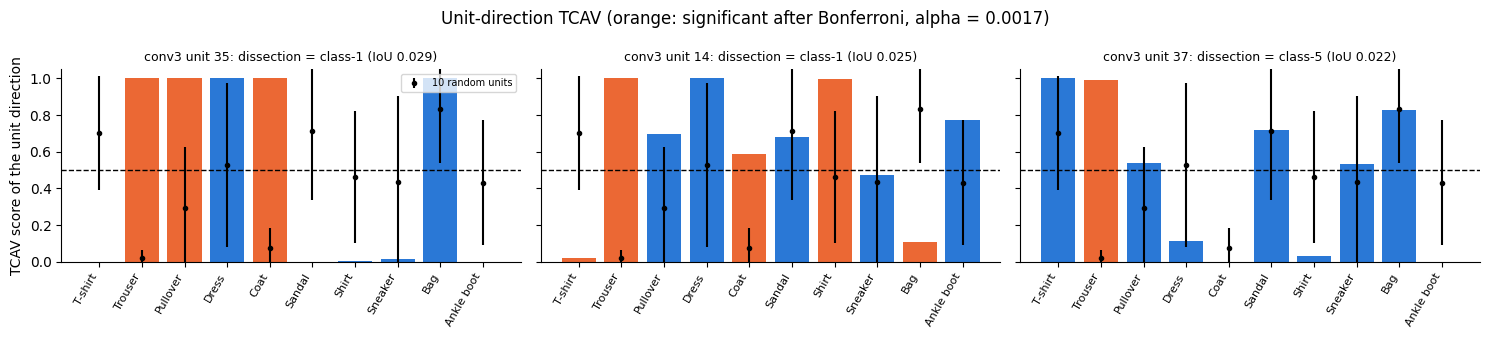

unit 35: dissection label class-1 | TCAV most sensitive class = Trouser (score 1.00, p = 0.0000) | match = True | classes sharing the top score: 5
unit 14: dissection label class-1 | TCAV most sensitive class = Trouser (score 1.00, p = 0.0000) | match = True | classes sharing the top score: 2
unit 37: dissection label class-5 | TCAV most sensitive class = T-shirt (score 1.00, p = 0.0187) | match = False | classes sharing the top score: 1


In [15]:
rows3 = dissection["conv3"][0]
cls_units = sorted([r for r in rows3 if r["concept"].startswith("class-")], key=lambda r: -r["iou"])
sel = cls_units[:3]
if len(sel) < 3:                                           # fall back to top units by IoU overall
    extra = [r for r in sorted(rows3, key=lambda r: -r["iou"]) if r["unit"] not in [s["unit"] for s in sel]]
    sel += extra[: 3 - len(sel)]
sel_units = [r["unit"] for r in sel]
print("Selected conv3 units:", [(r["unit"], r["concept"], round(r["iou"], 3)) for r in sel])

D3 = 64 * 7 * 7
def unit_cav(u):
    v = np.zeros(D3); v[u * 49:(u + 1) * 49] = 1.0
    return v / np.linalg.norm(v)

grads3 = {k: class_grads("conv3", k) for k in range(10)}
rng_u = np.random.default_rng(SEED)
null_units = rng_u.choice([u for u in range(64) if u not in sel_units], 10, replace=False)
null_scores = {k: np.array([tcav_score(grads3[k], unit_cav(u)) for u in null_units]) for k in range(10)}

unit_tcav, unit_p = {}, {}
for u in sel_units:
    unit_tcav[u] = np.array([tcav_score(grads3[k], unit_cav(u)) for k in range(10)])
    unit_p[u] = np.array([stats.ttest_1samp(null_scores[k], popmean=unit_tcav[u][k]).pvalue for k in range(10)])
    unit_p[u] = np.nan_to_num(unit_p[u], nan=1.0)

alpha_b = 0.05 / (len(sel_units) * 10)
fig, axes = plt.subplots(1, len(sel_units), figsize=(5 * len(sel_units), 3.4), sharey=True)
axes = np.atleast_1d(axes)
for ax, r in zip(axes, sel):
    u = r["unit"]
    ax.bar(range(10), unit_tcav[u], color=[C_ORANGE if p < alpha_b else C_BLUE for p in unit_p[u]],
           hatch=None); ax.axhline(0.5, ls="--", color="k", lw=1)
    ax.errorbar(range(10), [null_scores[k].mean() for k in range(10)], [null_scores[k].std() for k in range(10)], fmt="o", color="k", ms=3, label="10 random units")
    ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=60, ha="right", fontsize=8); ax.set_ylim(0, 1.05)
    ax.set_title(f"conv3 unit {u}: dissection = {r['concept']} (IoU {r['iou']:.3f})", fontsize=9)
axes[0].set_ylabel("TCAV score of the unit direction"); axes[0].legend(fontsize=7)
plt.suptitle(f"Unit-direction TCAV (orange: significant after Bonferroni, alpha = {alpha_b:.4f})"); plt.tight_layout(); plt.show()

for r in sel:
    u = r["unit"]; k = int(np.lexsort((unit_p[u], -unit_tcav[u]))[0])      # highest score, ties broken by smaller p
    n_tied = int((unit_tcav[u] >= unit_tcav[u].max() - 1e-9).sum())
    print(f"unit {u}: dissection label {r['concept']} | TCAV most sensitive class = {CLASSES[k]} (score {unit_tcav[u][k]:.2f}, p = {unit_p[u][k]:.4f})"
          f" | match = {r['concept'] == f'class-{k}'} | classes sharing the top score: {n_tied}")

### 5.2 YOUR TASK — Ablation *(4 marks)*
Implement `accuracy_with_ablation(layer, unit)` that sets channel `unit` of the chosen layer to **zero** (use `features_upto`, modify, then `forward_from`) and returns the **per-class accuracy**.

* Ablate each unit selected in 5.1 and plot the **per-class accuracy drop** (baseline − ablated).
* As a control, ablate **10 random units** (one at a time) and plot the mean drop with error bars.

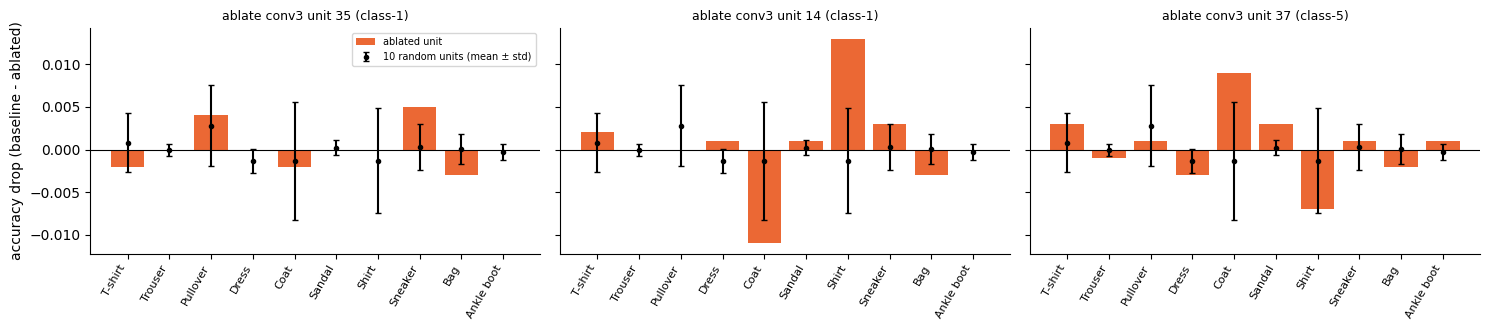

,unit,"dissection (label, IoU)",TCAV top class (score),ablation: most damaged class (drop),random-unit drop for that class
0,35,"class-1, 0.029",Trouser (1.00),Sneaker (0.005),0.000 ± 0.003
1,14,"class-1, 0.025",Trouser (1.00),Shirt (0.013),-0.001 ± 0.006
2,37,"class-5, 0.022",T-shirt (1.00),Coat (0.009),-0.001 ± 0.007


In [16]:
@torch.no_grad()
def accuracy_with_ablation(layer, unit):
    """Return per-class accuracy (array of 10) after zeroing channel `unit` in `layer`."""
    model.eval()
    out = []
    for i in range(0, len(X_test_raw), 512):
        x = normalize(X_test_raw[i:i + 512, None]).to(device)
        a = model.features_upto(x, layer).clone()
        a[:, unit] = 0.0
        out.append(model.forward_from(a, layer).argmax(1).cpu())
    p = torch.cat(out)
    return np.array([(p[y_test == k] == k).float().mean().item() for k in range(10)])

base_acc = np.array([(predict(model, X_test_raw)[y_test == k] == k).float().mean().item() for k in range(10)])
ctrl_units = [u for u in np.random.default_rng(SEED + 7).permutation(64) if u not in sel_units][:10]
ctrl_drops = np.stack([base_acc - accuracy_with_ablation("conv3", u) for u in ctrl_units])       # (10 units, 10 classes)
ctrl_mean, ctrl_std = ctrl_drops.mean(0), ctrl_drops.std(0)

sel_drops = {r["unit"]: base_acc - accuracy_with_ablation("conv3", r["unit"]) for r in sel}
fig, axes = plt.subplots(1, len(sel), figsize=(5 * len(sel), 3.4), sharey=True)
axes = np.atleast_1d(axes)
for ax, r in zip(axes, sel):
    ax.bar(range(10), sel_drops[r["unit"]], color=C_ORANGE, label="ablated unit")
    ax.errorbar(range(10), ctrl_mean, ctrl_std, fmt="o", color="k", ms=3, capsize=2, label="10 random units (mean ± std)")
    ax.axhline(0, color="k", lw=0.8); ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=60, ha="right", fontsize=8)
    ax.set_title(f"ablate conv3 unit {r['unit']} ({r['concept']})", fontsize=9)
axes[0].set_ylabel("accuracy drop (baseline - ablated)"); axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

# 5.3 synthesis table
syn = []
for r in sel:
    u = r["unit"]; k_t = int(np.lexsort((unit_p[u], -unit_tcav[u]))[0]); k_a = int(sel_drops[u].argmax())
    syn.append({"unit": u, "dissection (label, IoU)": f"{r['concept']}, {r['iou']:.3f}",
                "TCAV top class (score)": f"{CLASSES[k_t]} ({unit_tcav[u][k_t]:.2f})",
                "ablation: most damaged class (drop)": f"{CLASSES[k_a]} ({sel_drops[u][k_a]:.3f})",
                "random-unit drop for that class": f"{ctrl_mean[k_a]:.3f} ± {ctrl_std[k_a]:.3f}"})
display(pd.DataFrame(syn))

### 5.3 Synthesis *(1 mark)*
Build a small table: for each selected unit list **(dissection label, IoU) — (TCAV top class, score) — (ablation: most damaged class, drop)**. Do the three methods agree? If not, offer one explanation (e.g. redundancy between units, distributed representations).

*…*

---
## Part 6 — Report & reflection *(5 marks)*

Write a concise report (**≤ 400 words**) in the cell below covering:

1. **Findings [2 marks]:** the two or three most important results, each backed by a number or figure from this notebook.
2. **Agreement/disagreement [1 mark]:** where did TCAV, Dissection and ablation agree or disagree?
3. **Limitations [1 mark]:** at least two limitations *specific to your experiments* (concept design, confounds, small dissection set, thresholds, random seeds).
4. **Extension [1 mark]:** one concrete follow-up experiment you would run next, with a hypothesis and how you would test it.

**Report:**

*…*

---
## Submission checklist
- [ ] Notebook runs top-to-bottom without errors (*Runtime → Restart and run all*).
- [ ] All `# TODO` sections completed; all figures have titles and axis labels.
- [ ] Hypotheses written **before** the results they refer to.
- [ ] Random seeds fixed and stated.
- [ ] All **Answer** cells filled in.

## Marking rubric (summary)

| Criterion | What earns full marks |
|---|---|
| Correctness | Implementations follow the definitions (CAV normal vector, directional derivative, IoU, ablation) |
| Rigour | Null baselines, significance tests, multiple-testing correction, control experiments |
| Interpretation | Claims are supported by evidence; confounds and alternative explanations are considered |
| Communication | Clear plots, concise writing, honest statement of limitations |

## Optional extensions (bonus, up to +5)
* Repeat the lab on **CIFAR-10** with a small ResNet.
* Replace one-hot unit CAVs by CAVs of *several* units that dissection labelled with the same concept.
* Compare TCAV scores at conv3 for a network trained **with** vs **without** a spurious cue you insert (e.g. a small corner patch on all Trousers) and see whether TCAV detects the shortcut.

## References
* Kim, B. et al. (2018). *Interpretability Beyond Feature Attribution: Quantitative Testing with Concept Activation Vectors (TCAV).* ICML.
* Bau, D. et al. (2017). *Network Dissection: Quantifying Interpretability of Deep Visual Representations.* CVPR.
* Xiao, H. et al. (2017). *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms.* arXiv:1708.07747